# House Rent Prediction (Real Estate, Nigeria)
Capstone project: clean the raw data, explore it, train a regression model and save it for Streamlit.

**Target:** `annual_rent` (NGN per year). This is a **regression** problem because we predict a number, not a category.

### 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')

### 2. Load the raw data

In [2]:
Raw_Data = pd.read_csv('house_rent_dataset.csv')
Raw_Data.head()

,property_id,state,area_type,property_type,bedrooms,bathrooms,toilets,size_sqm,building_age_years,furnishing,has_generator,has_borehole,has_security,parking_spaces,distance_to_city_centre_km,power_supply_hours,annual_rent
0,PR42895,Abuja,Suburban,Flat,2,2,2,67.4,22.0,Furnished,1,1,1,1,16.9,3.4,786700.0
1,PR42988,Abuja,Rural,Flat,1,1,2,57.6,22.0,Unfurnished,1,0,1,1,24.1,7.5,239200.0
2,PR40228,Kaduna,Suburban,Duplex,4,4,5,143.5,6.0,Unfurnished,1,0,1,1,14.4,6.4,514600.0
3,PR42410,Enugu,Rural,Terrace,1,1,1,47.0,28.0,Unfurnished,0,1,1,0,47.8,6.2,92400.0
4,PR42692,Oyo,Urban,Terrace,3,2,2,99.2,18.0,Furnished,0,1,0,0,2.9,16.0,802400.0


In [3]:
Raw_Data.shape

(3030, 17)

In [4]:
Raw_Data.info()

<class 'pandas.DataFrame'>
RangeIndex: 3030 entries, 0 to 3029
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   property_id                 3030 non-null   str    
 1   state                       3030 non-null   str    
 2   area_type                   2980 non-null   str    
 3   property_type               3030 non-null   str    
 4   bedrooms                    3030 non-null   int64  
 5   bathrooms                   3030 non-null   int64  
 6   toilets                     3030 non-null   int64  
 7   size_sqm                    3030 non-null   str    
 8   building_age_years          2949 non-null   float64
 9   furnishing                  3030 non-null   str    
 10  has_generator               3030 non-null   str    
 11  has_borehole                3030 non-null   str    
 12  has_security                3030 non-null   str    
 13  parking_spaces              3030 non-null   

### 3. Data cleaning
Work on a copy so the raw data stays untouched.

In [5]:
ClData = Raw_Data.copy()

#### 3.1 Duplicate rows

In [6]:
print('Duplicate rows:', ClData.duplicated().sum())
ClData = ClData.drop_duplicates().reset_index(drop=True)
ClData.shape

Duplicate rows: 30


(3000, 17)

#### 3.2 Missing values

In [7]:
ClData.isnull().sum()

property_id                     0
state                           0
area_type                      50
property_type                   0
bedrooms                        0
bathrooms                       0
toilets                         0
size_sqm                        0
building_age_years             80
furnishing                      0
has_generator                   0
has_borehole                    0
has_security                    0
parking_spaces                  0
distance_to_city_centre_km      0
power_supply_hours            120
annual_rent                     0
dtype: int64

#### 3.3 state: typos and extra spaces

In [8]:
ClData['state'].value_counts()

state
Ogun       316
Delta      315
Oyo        306
Kaduna     300
Anambra    293
Lagos      277
Rivers     271
Kano       269
Abuja      266
Enugu      262
kano        25
Abuja       25
Lagoss      25
Enuggu      25
Rivers1     25
Name: count, dtype: int64

In [9]:
ClData['state'] = ClData['state'].str.strip().str.title()
ClData['state'] = ClData['state'].replace({'Lagoss': 'Lagos', 'Rivers1': 'Rivers', 'Enuggu': 'Enugu'})
ClData['state'].value_counts()

state
Ogun       316
Delta      315
Oyo        306
Lagos      302
Kaduna     300
Rivers     296
Kano       294
Anambra    293
Abuja      291
Enugu      287
Name: count, dtype: int64

#### 3.4 property_type: spelling variations

In [10]:
ClData['property_type'].value_counts()

property_type
Flat            1188
Bungalow         464
Duplex           443
Self-Contain     442
Terrace          410
flat              42
Self Contain      11
Name: count, dtype: int64

In [11]:
ClData['property_type'] = ClData['property_type'].str.strip().replace({'Self Contain': 'Self-Contain', 'flat': 'Flat'})
ClData['property_type'].value_counts()

property_type
Flat            1230
Bungalow         464
Self-Contain     453
Duplex           443
Terrace          410
Name: count, dtype: int64

#### 3.5 furnishing: upper and lower case mix

In [12]:
ClData['furnishing'] = ClData['furnishing'].str.strip().str.title()
ClData['furnishing'].value_counts()

furnishing
Unfurnished       1636
Semi-Furnished     782
Furnished          582
Name: count, dtype: int64

#### 3.6 size_sqm: some rows contain the word `sqm`

In [13]:
ClData['size_sqm'] = ClData['size_sqm'].astype(str).str.extract(r'(\d+\.?\d*)')[0]
ClData['size_sqm'] = pd.to_numeric(ClData['size_sqm'])
ClData['size_sqm'].describe().round(1)

count    3000.0
mean       82.9
std        30.3
min        21.7
25%        57.3
50%        79.6
75%       104.3
max       201.4
Name: size_sqm, dtype: float64

#### 3.7 annual_rent (target): `NGN` and commas make it text

In [14]:
ClData['annual_rent'] = (ClData['annual_rent'].astype(str)
                          .str.replace('NGN', '', regex=False)
                          .str.replace(',', '', regex=False).str.strip())
ClData['annual_rent'] = pd.to_numeric(ClData['annual_rent'])
ClData['annual_rent'].describe().round(0)

count       3000.0
mean      579682.0
std       366616.0
min        70200.0
25%       327000.0
50%       496700.0
75%       733625.0
max      3289700.0
Name: annual_rent, dtype: float64

#### 3.8 has_generator, has_borehole, has_security: Yes/No mixed with 1/0

In [15]:
yn_cols = ['has_generator', 'has_borehole', 'has_security']
for col in yn_cols:
    ClData[col] = (ClData[col].astype(str).str.strip().str.title()
                   .replace({'Yes': 1, 'No': 0, '1': 1, '0': 0}).astype(int))
ClData[yn_cols].apply(pd.Series.value_counts)

,has_generator,has_borehole,has_security
0,1697,1514,1340
1,1303,1486,1660


#### 3.9 Impossible values (outliers)
Bedrooms must be between 1 and 8, and power supply between 0 and 24 hours per day.

In [16]:
print(ClData['bedrooms'].describe())
print(ClData['power_supply_hours'].describe())

count    3000.000000
mean        2.123667
std         2.200149
min        -2.000000
25%         1.000000
50%         2.000000
75%         3.000000
max        99.000000
Name: bedrooms, dtype: float64
count    2880.000000
mean       10.114444
std         5.113616
min        -5.000000
25%         6.500000
50%        10.000000
75%        13.400000
max        99.000000
Name: power_supply_hours, dtype: float64


In [17]:
bad_beds = ~ClData['bedrooms'].between(1, 8)
bad_power = ClData['power_supply_hours'].notna() & ~ClData['power_supply_hours'].between(0, 24)
print('Invalid bedrooms:', bad_beds.sum(), '| Invalid power hours:', bad_power.sum())

ClData.loc[bad_beds, 'bedrooms'] = ClData.loc[~bad_beds, 'bedrooms'].median()
ClData.loc[bad_power, 'power_supply_hours'] = np.nan      # treat as missing, filled next
ClData['bedrooms'] = ClData['bedrooms'].astype(int)

Invalid bedrooms: 5 | Invalid power hours: 4


#### 3.10 Fill missing values
Numeric columns use the **median**, categorical columns use the **mode**.

In [18]:
ClData['power_supply_hours'] = ClData['power_supply_hours'].fillna(ClData['power_supply_hours'].median())
ClData['building_age_years'] = ClData['building_age_years'].fillna(ClData['building_age_years'].median())
ClData['area_type'] = ClData['area_type'].fillna(ClData['area_type'].mode()[0])

ClData.isnull().sum().sum()   # should be 0

np.int64(0)

#### 3.11 Save the clean file

In [19]:
ClData.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   property_id                 3000 non-null   str    
 1   state                       3000 non-null   str    
 2   area_type                   3000 non-null   str    
 3   property_type               3000 non-null   str    
 4   bedrooms                    3000 non-null   int64  
 5   bathrooms                   3000 non-null   int64  
 6   toilets                     3000 non-null   int64  
 7   size_sqm                    3000 non-null   float64
 8   building_age_years          3000 non-null   float64
 9   furnishing                  3000 non-null   str    
 10  has_generator               3000 non-null   int64  
 11  has_borehole                3000 non-null   int64  
 12  has_security                3000 non-null   int64  
 13  parking_spaces              3000 non-null   

In [20]:
ClData.to_csv('house_rent_clean.csv', index=False)
ClData.shape

(3000, 17)

### 4. Exploratory analysis and KPIs

In [21]:
print(f"Total properties        : {len(ClData):,}")
print(f"Average annual rent     : NGN {ClData['annual_rent'].mean():,.0f}")
print(f"Median annual rent      : NGN {ClData['annual_rent'].median():,.0f}")
print(f"Highest annual rent     : NGN {ClData['annual_rent'].max():,.0f}")
print(f"Average rent per sqm    : NGN {(ClData['annual_rent'] / ClData['size_sqm']).mean():,.0f}")

Total properties        : 3,000
Average annual rent     : NGN 579,682
Median annual rent      : NGN 496,700
Highest annual rent     : NGN 3,289,700
Average rent per sqm    : NGN 7,222


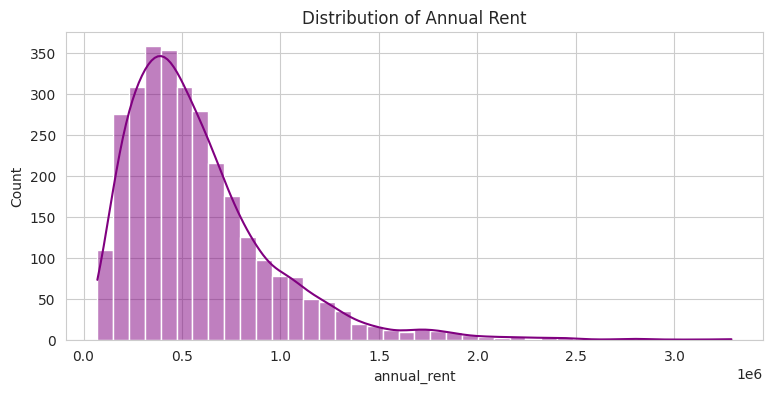

In [22]:
plt.figure(figsize=(9, 4))
sns.histplot(ClData['annual_rent'], bins=40, kde=True, color='purple')
plt.title('Distribution of Annual Rent'); plt.show()

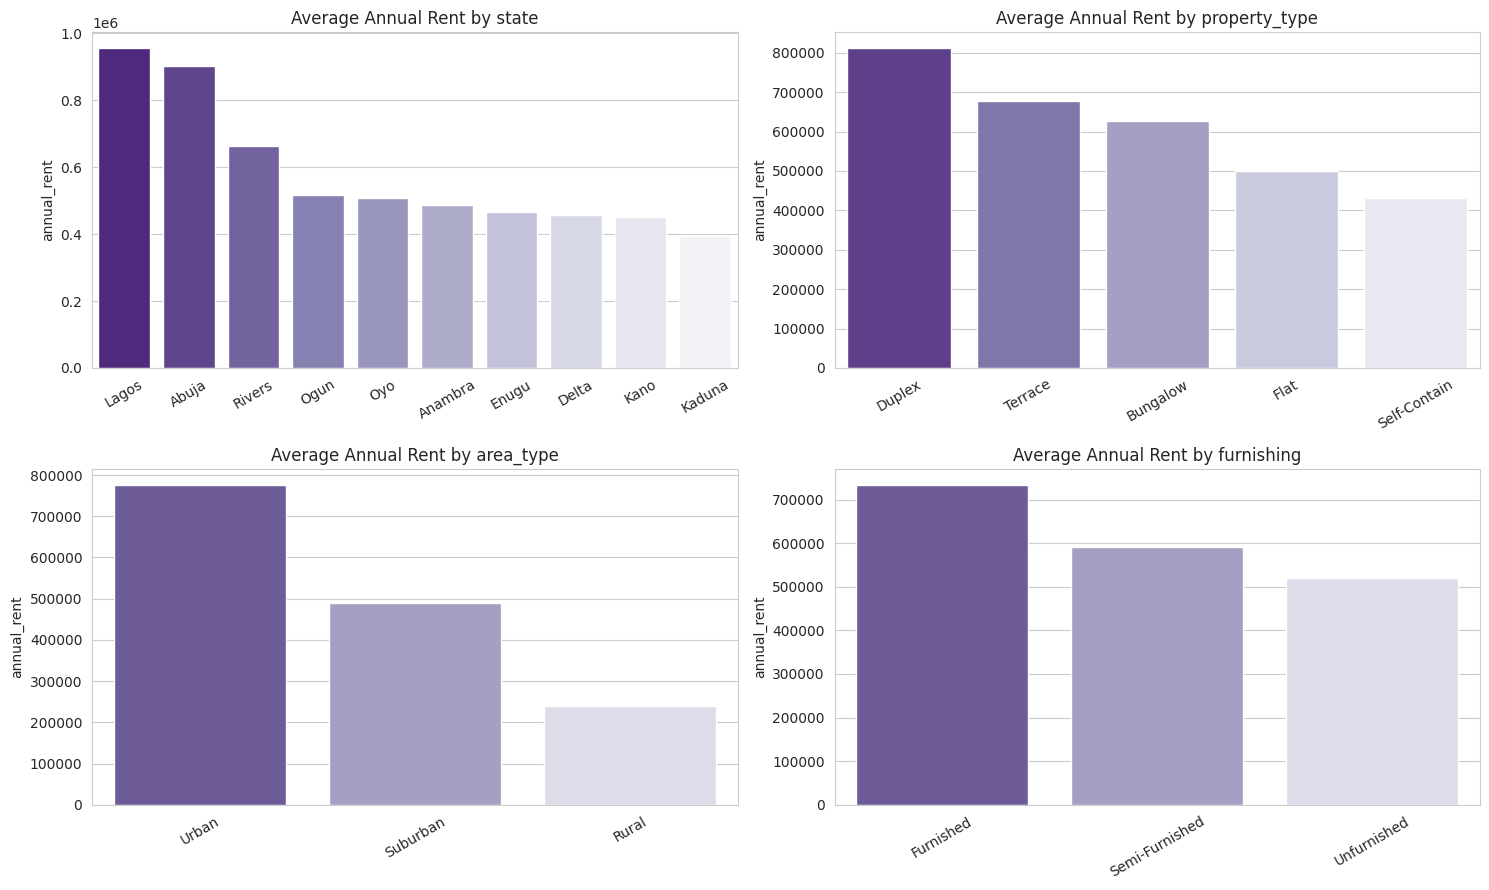

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, col in zip(axes.flatten(), ['state', 'property_type', 'area_type', 'furnishing']):
    avg = ClData.groupby(col)['annual_rent'].mean().sort_values(ascending=False).reset_index()
    sns.barplot(data=avg, x=col, y='annual_rent', hue=col, palette='Purples_r', ax=ax, legend=False)
    ax.set_title(f'Average Annual Rent by {col}'); ax.set_xlabel(''); ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

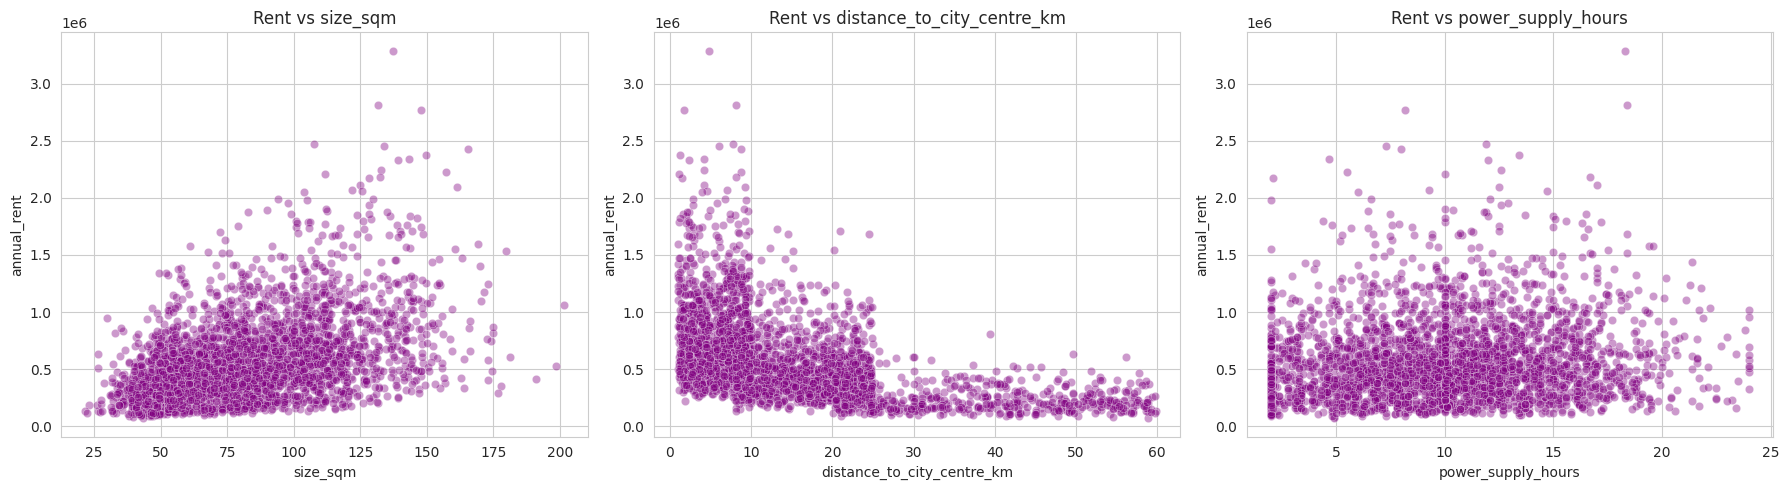

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col in zip(axes, ['size_sqm', 'distance_to_city_centre_km', 'power_supply_hours']):
    sns.scatterplot(data=ClData, x=col, y='annual_rent', alpha=.4, color='purple', ax=ax)
    ax.set_title(f'Rent vs {col}')
plt.tight_layout(); plt.show()

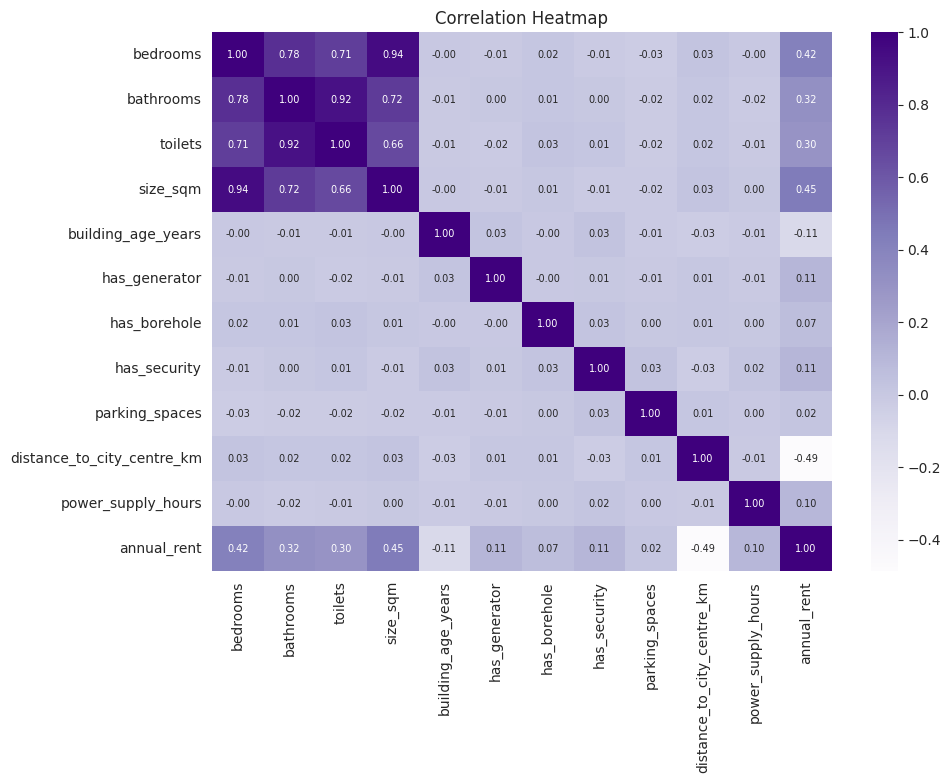

In [25]:
plt.figure(figsize=(10, 7))
sns.heatmap(ClData.select_dtypes('number').corr(), cmap='Purples', annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title('Correlation Heatmap'); plt.show()

### 5. Prepare data for machine learning
A `ColumnTransformer` inside a `Pipeline` scales the numbers and one-hot encodes the text columns. The saved model therefore accepts **raw values** like `'Lagos'` and `'Duplex'`.

In [26]:
numeric_cols = ['bedrooms', 'bathrooms', 'toilets', 'size_sqm', 'building_age_years',
                'parking_spaces', 'distance_to_city_centre_km', 'power_supply_hours']
binary_cols = ['has_generator', 'has_borehole', 'has_security']
categorical_cols = ['state', 'area_type', 'property_type', 'furnishing']

feature_cols = numeric_cols + binary_cols + categorical_cols
x = ClData[feature_cols]
y = ClData['annual_rent']
len(feature_cols)

15

### 6. Train / test split

In [27]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
x_train.shape, x_test.shape

((2400, 15), (600, 15))

### 7. Build and compare models
Rent is right-skewed, so we train on `log(rent)` using `TransformedTargetRegressor` and the predictions are converted back to naira automatically.

In [28]:
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols),
], remainder='passthrough')   # binary 0/1 columns pass through

models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
}

results, fitted = [], {}
for name, reg in models.items():
    pipe = TransformedTargetRegressor(
        regressor=Pipeline([('prep', preprocessor), ('reg', reg)]),
        func=np.log1p, inverse_func=np.expm1)
    pipe.fit(x_train, y_train)
    pred = pipe.predict(x_test)
    fitted[name] = pipe
    results.append({'Model': name,
                    'MAE (NGN)': mean_absolute_error(y_test, pred),
                    'RMSE (NGN)': np.sqrt(mean_squared_error(y_test, pred)),
                    'R2': r2_score(y_test, pred)})

results_df = pd.DataFrame(results).sort_values('R2', ascending=False).round(3)
results_df

,Model,MAE (NGN),RMSE (NGN),R2
0,Linear Regression,62373.943,87286.400,0.939
2,Gradient Boosting,75008.316,106433.492,0.909
1,Random Forest,91808.849,135459.341,0.853


**R2** shows how much of the variation in rent the model explains (1.0 is perfect). **MAE** is the average naira error per prediction. We choose the best model by R2.

Best model: Linear Regression


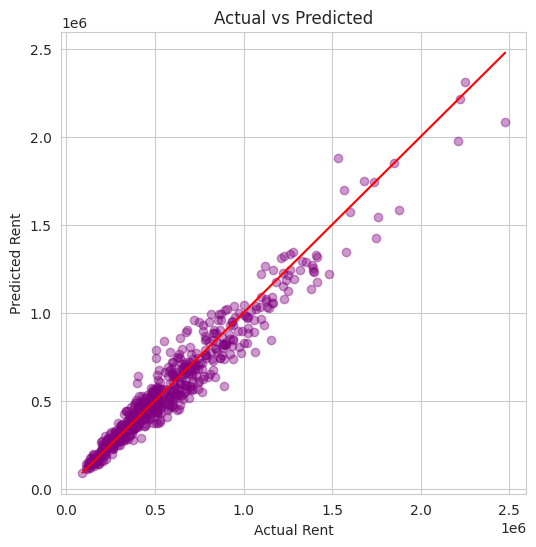

In [29]:
best_name = results_df.iloc[0]['Model']
best_model = fitted[best_name]
print('Best model:', best_name)

best_pred = best_model.predict(x_test)
plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_pred, alpha=.4, color='purple')
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, color='red')
plt.xlabel('Actual Rent'); plt.ylabel('Predicted Rent'); plt.title('Actual vs Predicted'); plt.show()

### 8. Check for overfitting

In [30]:
print('Train R2:', round(r2_score(y_train, best_model.predict(x_train)), 3))
print('Test R2 :', round(r2_score(y_test, best_pred), 3))

Train R2: 0.939
Test R2 : 0.939


### 9. Save the model for Streamlit

In [31]:
pickle.dump(best_model, open('model.sav', 'wb'))
pickle.dump(feature_cols, open('model_columns.sav', 'wb'))
print('Saved model.sav and model_columns.sav')

Saved model.sav and model_columns.sav


### 10. Test the saved model on one new property

In [32]:
load_model = pickle.load(open('model.sav', 'rb'))

new_property = pd.DataFrame([{
    'bedrooms': 3, 'bathrooms': 3, 'toilets': 4, 'size_sqm': 110, 'building_age_years': 5,
    'parking_spaces': 2, 'distance_to_city_centre_km': 8, 'power_supply_hours': 12,
    'has_generator': 1, 'has_borehole': 1, 'has_security': 1,
    'state': 'Abuja', 'area_type': 'Urban', 'property_type': 'Flat', 'furnishing': 'Semi-Furnished'}])

print(f'Predicted annual rent: NGN {load_model.predict(new_property)[0]:,.0f}')

Predicted annual rent: NGN 1,948,725
